# Recipe Rating Prediction

**Goal.** Predict the star rating (0–5) a user gave a recipe from their review text, their community signals (thumbs up/down, reputation, best score) and when they posted.

**Data.** 13,636 labelled reviews of 100 recipes (`data/train.csv`) and 4,546 unlabelled reviews (`data/test.csv`). The metric is **accuracy**.

**Approach.**
1. EDA: understand the target and every column.
2. Feature engineering: time features, vote features, text statistics. Identifier columns are dropped.
3. One sklearn `Pipeline`: numeric scaling, one-hot encoding, TF-IDF on the review text, then the model.
4. Compare baseline → linear → KNN → bagging (Random Forest) → boosting (LightGBM, XGBoost), tune, then **stack** them.
5. Report accuracy **and macro-F1**, because the classes are heavily imbalanced.

The heavy training lives in `src/train.py` (`python -m src.train`). This notebook explains the data and reads its results.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report

from src.features import add_features, build_preprocessor, TARGET, NUMERIC_COLS, CATEGORICAL_COLS
from src.models import make_pipeline, logreg, lightgbm

sns.set_theme(style="whitegrid")
train = pd.read_csv(ROOT / "data" / "train.csv")
test = pd.read_csv(ROOT / "data" / "test.csv")
print("train:", train.shape, " test:", test.shape)
train.head(3)

train: (13636, 15)  test: (4546, 14)


,ID,RecipeNumber,RecipeCode,RecipeName,CommentID,UserID,UserName,UserReputation,CreationTimestamp,ReplyCount,ThumbsUpCount,ThumbsDownCount,Rating,BestScore,Recipe_Review
0,70,71,12259,Banana Bars with Cream Cheese Frosting,sp_aUSaElGf_12259_c_149978,u_1oKVaBmiEKwAFyiHrDLoWpbel0J,misscoffeepot,20,1622717078,0,0,0,5,100,great recipe! I have made them just as written...
1,72,88,8202,Simple Taco Soup,sp_aUSaElGf_8202_c_310332,u_1oKZeRIXYzGNhGW8OMR3O4lX1ih,MichelleMalone,1,1622717852,0,0,1,5,100,This is an easy and quick recipe that is great...
2,458,3,2832,Cheeseburger Soup,sp_aUSaElGf_2832_c_206522,u_1oKYHUtdaD48KJCDYq5wfpAUxWz,jeannem32,1,1622717357,0,0,0,3,100,I think I was looking for something extra spec...


## 1. EDA
### 1.1 Columns, types, missing values

In [2]:
train.info()
print("\nMissing values:\n", train.isnull().sum()[train.isnull().sum() > 0])
print("\nUnique values per column:\n", train.nunique().sort_values())

<class 'pandas.DataFrame'>
RangeIndex: 13636 entries, 0 to 13635
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   ID                 13636 non-null  int64
 1   RecipeNumber       13636 non-null  int64
 2   RecipeCode         13636 non-null  int64
 3   RecipeName         13636 non-null  str  
 4   CommentID          13636 non-null  str  
 5   UserID             13636 non-null  str  
 6   UserName           13636 non-null  str  
 7   UserReputation     13636 non-null  int64
 8   CreationTimestamp  13636 non-null  int64
 9   ReplyCount         13636 non-null  int64
 10  ThumbsUpCount      13636 non-null  int64
 11  ThumbsDownCount    13636 non-null  int64
 12  Rating             13636 non-null  int64
 13  BestScore          13636 non-null  int64
 14  Recipe_Review      13634 non-null  str  
dtypes: int64(10), str(5)
memory usage: 1.6 MB

Missing values:
 Recipe_Review    2
dtype: int64

Unique values per colu

**Observations**
- Only `Recipe_Review` has missing values (2 rows). We **keep** these rows and treat the review as empty text, instead of dropping them.
- `CommentID` is unique per row, so it's an identifier. `UserID`/`UserName` have about 10.8k unique values for 13.6k rows, so most users appear once. These can't generalise and are dropped.
- `RecipeNumber`, `RecipeCode` and `RecipeName` all identify the same 100 recipes. We keep only `RecipeName`, one-hot encoded. Feeding codes as numbers would wrongly imply that recipe 200 is "bigger" than recipe 100.

### 1.2 The target: very imbalanced

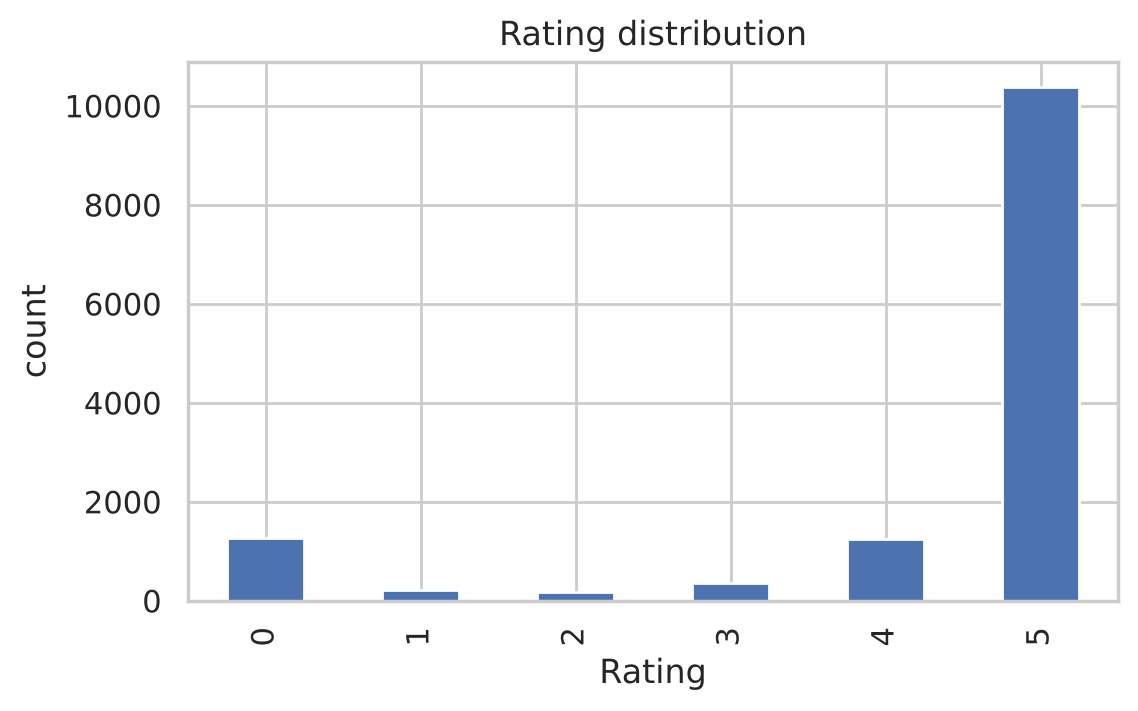

Rating
0     9.3 %
1     1.5 %
2     1.3 %
3     2.7 %
4     9.1 %
5    76.1 %
Name: proportion, dtype: str


In [3]:
ax = train[TARGET].value_counts().sort_index().plot.bar(color="#4C72B0", figsize=(6, 3.5))
ax.set_title("Rating distribution"); ax.set_xlabel("Rating"); ax.set_ylabel("count")
plt.show()
print((train[TARGET].value_counts(normalize=True).sort_index() * 100).round(1).astype(str) + " %")

**76% of reviews are rated 5.** A "model" that always predicts 5 already scores **0.76 accuracy**. That baseline is what every real model must beat, and it's why we also report **macro-F1**, which averages F1 over all six classes equally.

**Rating 0** isn't "zero stars". These are comments posted *without* a star rating (questions, notes like "I'm going to try this"). That's why 0 behaves differently from 1–2.

In [4]:
for r in [0, 1, 5]:
    print(f"Rating {r}:", train.loc[train[TARGET] == r, "Recipe_Review"].head(2).tolist(), "\n")

Rating 0: ['I made this. ..something wrong with this recipe. I didn&#39;t adjust. I prefer the Eagle brand milk recipe', 'I&#39;m going to try this, bet it is good. Lived in East Bethel, MN 10 years. As I read through the recipe I thought &#34;Where is the cream of mushroom soup???&#34; Then I saw it.'] 



Rating 1: ['Did not care for this recipe.  Lasagna was very juicy. Also to much salt.  Prefer a baked version.', 'Where do I start..... Way to sweet, the corn &amp; sweet peas DO NOT make good lovers. This isn&#39;t any 30 minute meal by a VERY long shot. Maybe a few peas and carrots. I used tomato paste instead of ketchup. I can only imagine how sweet it would&#39;ve been with the ketchup. I used beef broth( I never like the granules or cubes). The after taste makes me want to hurl right now. I hate throwing food in the garbage but another meal of this wasn&#39;t going to happen. I even added some fresh ground pepper to cut the sweetness. Thank the heavens for pepper. I looked forward to eating this recipe and I am very bummed about throwing $$$$ down the drain. Fellow culinary participants...Stay away from this recipe. Very sad right now. If I could give no stars I would.'] 

Rating 5: ['great recipe! I have made them just as written, wonderfull, moist, delicate flavor...then the nex

### 1.3 Numeric signals vs rating

,UserReputation,ReplyCount,ThumbsUpCount,ThumbsDownCount,BestScore
Rating,,,,,
0,1.63,0.06,1.82,1.06,175.00
1,1.93,0.06,0.82,5.50,122.55
2,1.83,0.07,1.57,2.93,152.09
3,2.29,0.05,1.13,1.96,154.40
4,2.52,0.02,1.01,0.59,149.29
5,2.19,0.01,1.02,0.28,151.50


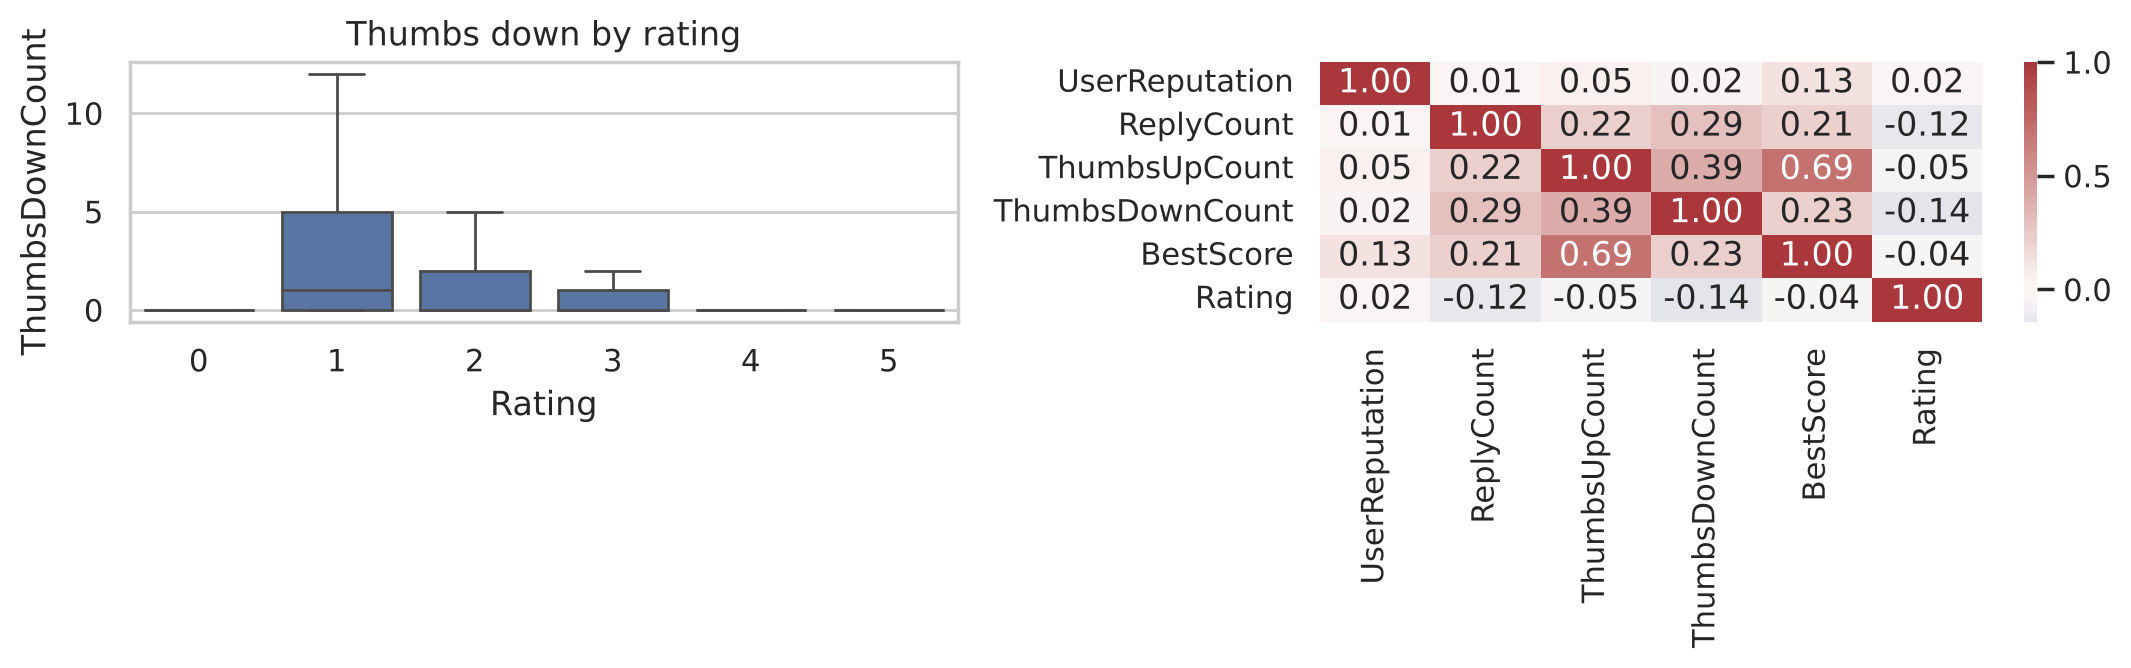

In [5]:
num = ["UserReputation", "ReplyCount", "ThumbsUpCount", "ThumbsDownCount", "BestScore"]
display(train.groupby(TARGET)[num].mean().round(2))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.boxplot(data=train, x=TARGET, y="ThumbsDownCount", ax=axes[0], showfliers=False).set_title("Thumbs down by rating")
sns.heatmap(train[num + [TARGET]].corr(), annot=True, fmt=".2f", cmap="vlag", center=0, ax=axes[1])
plt.tight_layout(); plt.show()

**Observations**
- Low ratings get more thumbs-down: a 1-star review averages about 5.5 thumbs-down against 0.3 for a 5-star one. The community disagrees with harsh reviews, so this is a useful signal.
- The counts are heavy-tailed (mostly 0, with a few above 100). We apply a signed `log1p` before scaling instead of deleting "outliers". The test set has the same extreme values, so a model trained without them would be surprised.
- Linear correlations with rating are weak. Most of the signal is in the **text**.

## 2. Feature engineering

In [6]:
X = add_features(train.drop(columns=[TARGET]))
y = train[TARGET]
X_test = add_features(test)
print("Numeric:", NUMERIC_COLS)
print("Categorical:", CATEGORICAL_COLS)
X.head(3)

Numeric: ['UserReputation', 'ReplyCount', 'ThumbsUpCount', 'ThumbsDownCount', 'BestScore', 'Year', 'Month', 'Day', 'Hour', 'Weekend', 'WeightedVote', 'ReputationXVotes', 'ReviewLength', 'ExclamationCount', 'QuestionCount']
Categorical: ['RecipeName', 'DayOfWeek', 'TimeOfDay']


,RecipeName,UserReputation,ReplyCount,ThumbsUpCount,ThumbsDownCount,BestScore,Recipe_Review,Year,Month,Day,Hour,DayOfWeek,TimeOfDay,Weekend,WeightedVote,ReputationXVotes,ReviewLength,ExclamationCount,QuestionCount
0,Banana Bars with Cream Cheese Frosting,20,0,0,0,100,great recipe! I have made them just as written...,2021,6,3,10,Thursday,Morning,0,0,0,46,1,0
1,Simple Taco Soup,1,0,0,1,100,This is an easy and quick recipe that is great...,2021,6,3,10,Thursday,Morning,0,-1,1,74,0,0
2,Cheeseburger Soup,1,0,0,0,100,I think I was looking for something extra spec...,2021,6,3,10,Thursday,Morning,0,0,0,26,0,0


| Feature | Why |
|---|---|
| `Year, Month, Day, Hour, DayOfWeek, TimeOfDay, Weekend` | from `CreationTimestamp`; posting behaviour may differ by time |
| `WeightedVote` = up − down | net community agreement |
| `ReputationXVotes` = reputation × total votes | engagement weighted by how trusted the user is |
| `ReviewLength, ExclamationCount, QuestionCount` | "Delicious!!!" vs a long complaint vs a question (often rating 0) |
| TF-IDF of `Recipe_Review` (1–2 grams) | the actual words, e.g. "not good", "will make again" |

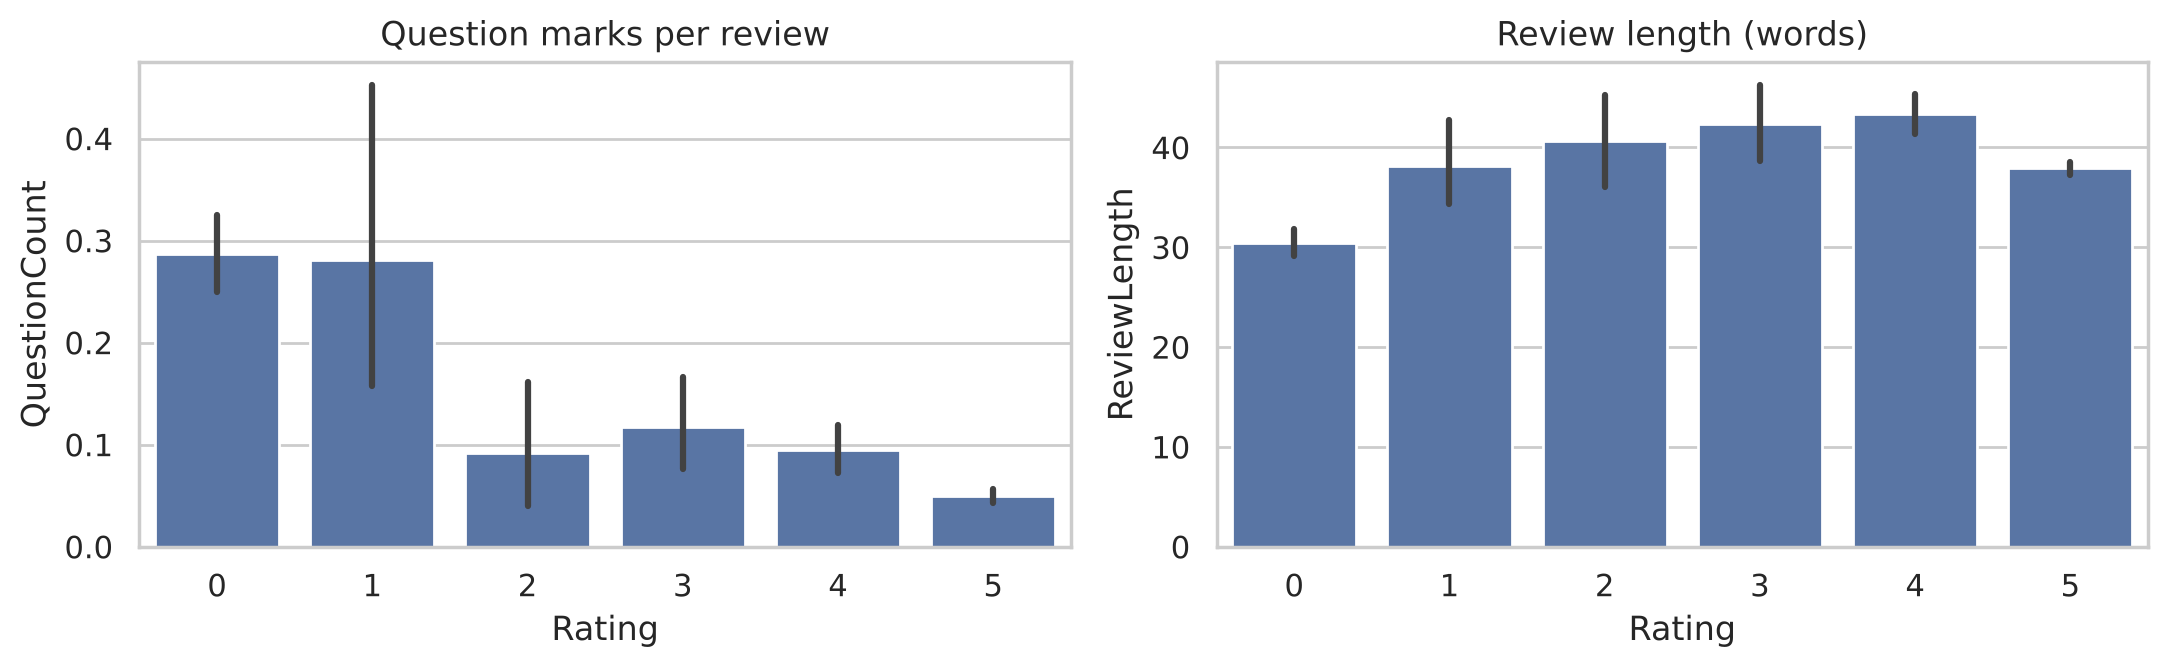

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.barplot(data=X.assign(Rating=y), x="Rating", y="QuestionCount", ax=axes[0]).set_title("Question marks per review")
sns.barplot(data=X.assign(Rating=y), x="Rating", y="ReviewLength", ax=axes[1]).set_title("Review length (words)")
plt.tight_layout(); plt.show()

## 3. Preprocessing pipeline

`build_preprocessor()` is a `ColumnTransformer`:
- **numeric** → median-impute → signed log1p → `StandardScaler`
- **categorical** → most-frequent impute → `OneHotEncoder(handle_unknown="ignore")`
- **text** → `TfidfVectorizer(ngram_range=(1,2), min_df=2, sublinear_tf=True, max_features=20000)`

The output is a **sparse** matrix: 13.6k rows × ~20k columns, almost all zeros. Keeping it sparse saves about 2 GB of RAM compared with `.toarray()`.

Because the preprocessor sits *inside* the model `Pipeline`, it's fit only on training data (and on training folds during CV). The validation and test rows never influence the TF-IDF vocabulary or the scaler, so there's no leakage.

In [8]:
X_tr, X_va, y_tr, y_va = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
prep = build_preprocessor().fit(X_tr)
Z = prep.transform(X_tr)
print("matrix:", Z.shape, f"| non-zeros: {Z.nnz / np.prod(Z.shape):.3%}")

matrix: (10908, 20126) | non-zeros: 0.341%


## 4. Quick demo: two models through the same pipeline

In [9]:
for name, est in [("Logistic Regression", logreg()), ("LightGBM", lightgbm())]:
    pipe = make_pipeline(est).fit(X_tr, y_tr)
    p = pipe.predict(X_va)
    print(f"{name:20s} val acc={accuracy_score(y_va, p):.4f}  macro-F1={f1_score(y_va, p, average='macro'):.4f}")

Logistic Regression  val acc=0.7841  macro-F1=0.3560


LightGBM             val acc=0.7889  macro-F1=0.3559


In [10]:
# Which words push a review towards 5 stars vs 1 star? (Logistic Regression coefficients)
lr_pipe = make_pipeline(logreg()).fit(X_tr, y_tr)
names = lr_pipe.named_steps["prep"].get_feature_names_out()
coef = lr_pipe.named_steps["model"].coef_
classes = list(lr_pipe.named_steps["model"].classes_)
for r in [1, 5]:
    top = np.argsort(coef[classes.index(r)])[-12:][::-1]
    print(f"Rating {r}:", [n.replace("text__", "") for n in names[top]])

Rating 1: ['not', 'awful', 'very bland', 'tasteless', 'too', 'gross', 'disappointed', 'much', 'sorry', 'at all', 'followed', 'bland']
Rating 5: ['fantastic', 'delicious', 'best', 'loved', 'every', 'amazing', 'great', 'everyone', 'yummy', 'used', 'wonderful', 'absolutely']


## 5. Full model comparison (from `python -m src.train`)

In [11]:
results = pd.read_csv(ROOT / "results" / "model_comparison.csv").sort_values("val_accuracy", ascending=False)
display(results)

,model,train_accuracy,val_accuracy,val_macro_f1,fit_seconds
8,Stacking (LR+LGBM+XGB+RF),0.9853,0.7984,0.3842,614.8
7,LightGBM (tuned),0.9625,0.7903,0.3280,19.6
5,XGBoost,0.9461,0.7900,0.3537,75.1
4,LightGBM,0.9911,0.7889,0.3559,22.6
1,Logistic Regression,0.9217,0.7841,0.3560,18.3
6,Logistic Regression (tuned),0.9552,0.7841,0.3714,22.1
3,Random Forest,0.9997,0.7753,0.2392,13.5
2,KNN,0.7748,0.7702,0.2606,5.2
0,Baseline (always 5),0.7605,0.7606,0.1440,1.0


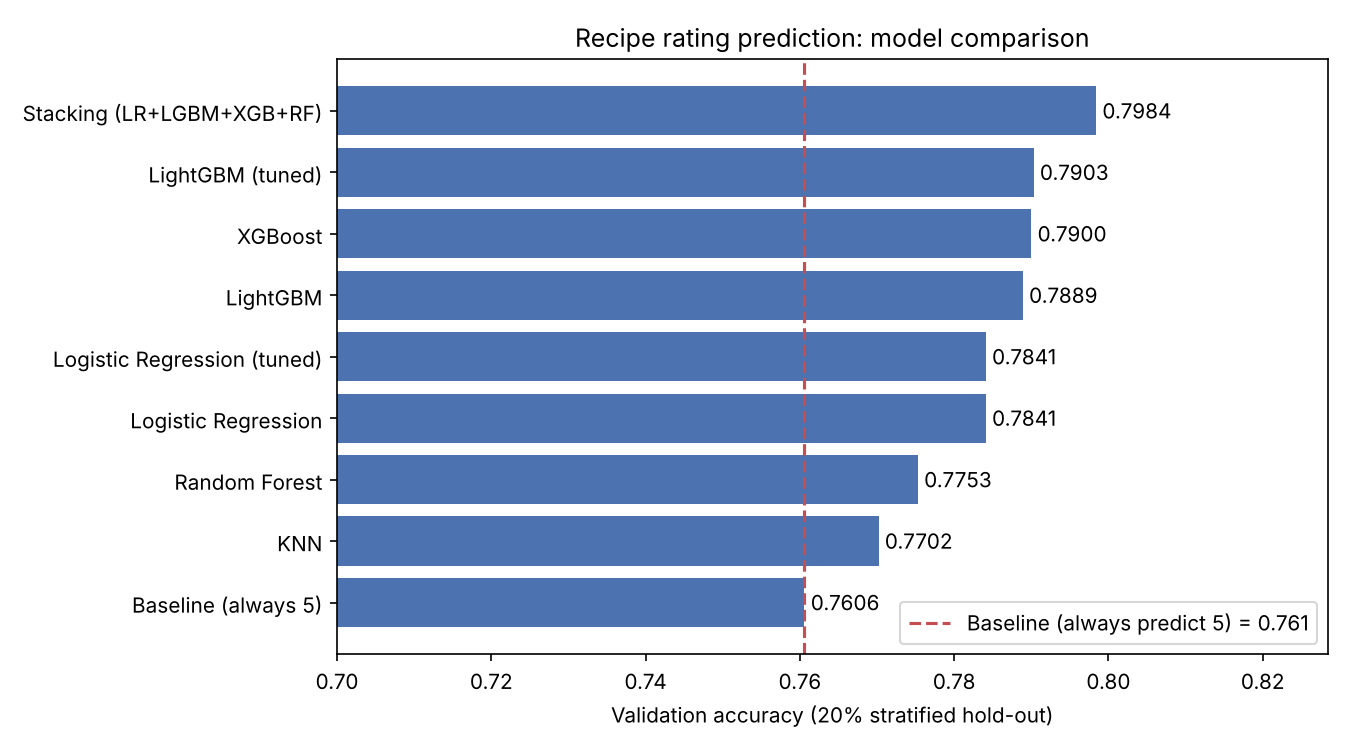

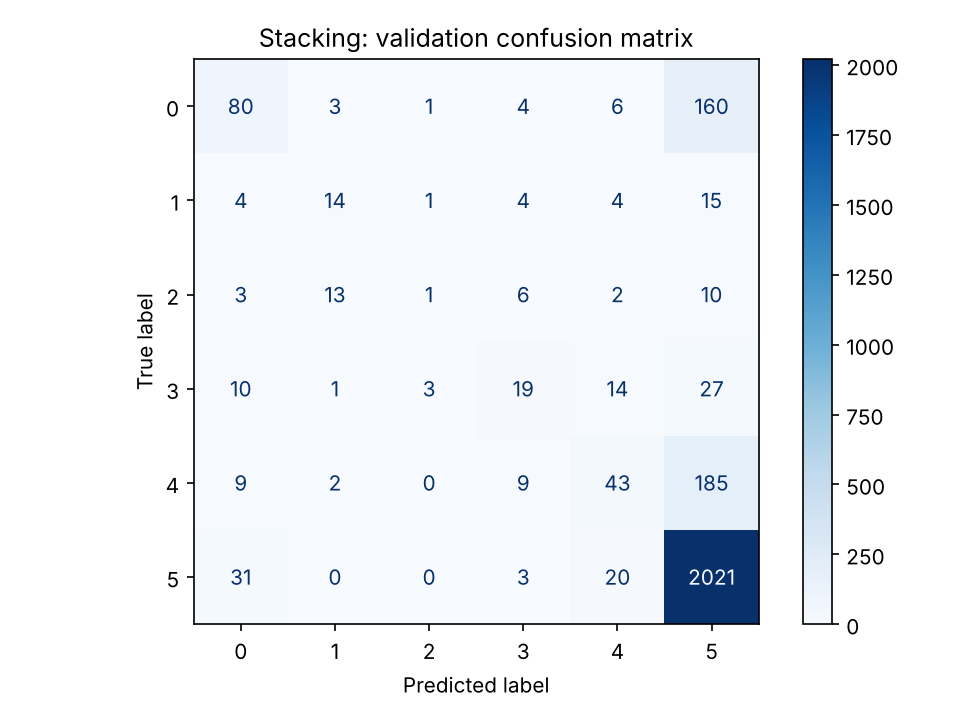

              precision    recall  f1-score   support

           0      0.584     0.315     0.409       254
           1      0.424     0.333     0.373        42
           2      0.167     0.029     0.049        35
           3      0.422     0.257     0.319        74
           4      0.483     0.173     0.255       248
           5      0.836     0.974     0.900      2075

    accuracy                          0.798      2728
   macro avg      0.486     0.347     0.384      2728
weighted avg      0.754     0.798     0.761      2728



In [12]:
from IPython.display import Image, display as show
show(Image(str(ROOT / "image" / "model_comparison.png"), width=700))
show(Image(str(ROOT / "image" / "confusion_matrix.png"), width=450))
print((ROOT / "results" / "stacking_classification_report.txt").read_text())

## 6. Conclusions

- **Baseline first.** Always predicting 5 gives **0.761** accuracy and **0.144** macro-F1. Every model has to be judged against that.
- **The stacking ensemble is best:** **0.798** validation accuracy and **0.384** macro-F1, with **0.80004** on the Kaggle public leaderboard.
- **Boosting > bagging here.** LightGBM and XGBoost (about 0.79) beat Random Forest (0.775), which memorises the training set (train accuracy about 1.0).
- **Logistic Regression is a strong text baseline** (0.784). TF-IDF features are close to linearly separable.
- **Tuning helped a little; features and ensembling helped more.** Tuned LR raised macro-F1 but not accuracy.
- **The real difficulty is the rare classes.** Ratings 1–3 are about 5% of the data combined. Class 2 is barely learned (F1 about 0.05), and class 0 (no rating) is often confused with 5.

**Next steps:** transformer embeddings (DistilBERT / sentence embeddings) for the text; class weighting or threshold tuning if minority recall matters more than accuracy; and a separate "has rating?" model for class 0.